<a href="https://colab.research.google.com/github/ImagingDataCommons/IDC-Tutorials/blob/master/notebooks/advanced_topics/gdc_clinical_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linking IDC images to GDC clinical data

Many patients in NCI Imaging Data Commons (IDC) are also cases in the NCI [Genomic Data Commons (GDC)](https://portal.gdc.cancer.gov/), which holds harmonized clinical records (diagnosis, stage, demographics, follow up) for them. For TCGA and CPTAC, IDC already ships clinical tables in `idc-index` (see [this tutorial](https://github.com/ImagingDataCommons/IDC-Tutorials/blob/master/notebooks/getting_started/exploring_clinical_data.ipynb)). For several other collections whose patients are GDC cases, `idc-index` has no clinical table, and the clinical data lives only in GDC.

In this notebook we will:

1. Find the IDC collections that have a matching GDC project, and see which of them have no clinical table in `idc-index`.
2. Fetch the clinical records for one of them, `cgci_htmcp_cc` (cervical cancer), from the public GDC API.
3. Join them to the IDC images on the patient identifier and tabulate histology against stage.
4. Show H&E and p16 slides for one patient of each histologic type, labeled with their clinical data.

Neither IDC nor GDC requires an account or a cloud project for this: `idc-index` searches a local copy of the IDC metadata, the GDC API is open, and the images are read from the public IDC bucket.

If you have never worked with IDC before, we recommend you first complete the getting started tutorial [here](https://github.com/ImagingDataCommons/IDC-Tutorials/blob/master/notebooks/getting_started/part2_searching_basics.ipynb).

Authored by Aaron Kanzer

---
Initial version: Nov 2026

Updated: Nov 2026

## Prerequisites

We need [`idc-index`](https://github.com/ImagingDataCommons/idc-index) to search IDC and download images, and `pydicom` to read them. `pandas`, `requests` and `matplotlib` are preinstalled in Colab.

In [1]:
%%capture
!pip install --upgrade idc-index pydicom

In [2]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pydicom
import requests
from idc_index import IDCClient

GDC_API = "https://api.gdc.cancer.gov"

c = IDCClient()
c.fetch_index("clinical_index")
c.fetch_index("sm_instance_index")
print("IDC data version:", c.get_idc_version())

IDC data version: v25


## Which IDC collections are GDC projects?

GDC project identifiers such as `CGCI-HTMCP-CC` become IDC collection identifiers by lowercasing and replacing dashes with underscores (`cgci_htmcp_cc`). We list all GDC projects with one API call, match them to IDC collections by name, and flag whether each collection has a clinical table in `idc-index`.

Matching by name misses some links. For example, the IDC collections `cptac_luad`, `cptac_ccrcc` and others all correspond to the single GDC project `CPTAC-3`. The name match is enough to find the gap, though.

In [3]:
response = requests.get(f"{GDC_API}/projects", params={"size": 1000, "fields": "project_id,summary.case_count"}, timeout=60)
response.raise_for_status()
gdc_projects = pd.DataFrame(
    [{"gdc_project": h["project_id"], "gdc_cases": h["summary"]["case_count"]} for h in response.json()["data"]["hits"]]
)
gdc_projects["collection_id"] = gdc_projects["gdc_project"].str.lower().str.replace("-", "_")

idc_collections = c.index.groupby("collection_id").agg(idc_patients=("PatientID", "nunique")).reset_index()

matched = gdc_projects.merge(idc_collections, on="collection_id")
matched["clinical_table_in_idc_index"] = matched["collection_id"].isin(c.clinical_index["collection_id"])

print(f"{len(matched)} IDC collections share a name with a GDC project")
matched.sort_values(["clinical_table_in_idc_index", "collection_id"]).reset_index(drop=True).head(10)

40 IDC collections share a name with a GDC project


,gdc_project,gdc_cases,collection_id,idc_patients,clinical_table_in_idc_index
0,CCDI-MCI,3076,ccdi_mci,4407,False
1,CDDP_EAGLE-1,50,cddp_eagle_1,49,False
2,CGCI-BLGSP,324,cgci_blgsp,388,False
3,CGCI-HTMCP-CC,212,cgci_htmcp_cc,211,False
4,CGCI-HTMCP-DLBCL,70,cgci_htmcp_dlbcl,43,False
5,CGCI-HTMCP-LC,39,cgci_htmcp_lc,27,False
6,HCMI-CMDC,805,hcmi_cmdc,382,False
7,TCGA-ACC,92,tcga_acc,92,True
8,TCGA-BLCA,412,tcga_blca,412,True
9,TCGA-BRCA,1098,tcga_brca,1098,True


The rows with `clinical_table_in_idc_index` equal to `False` are collections whose clinical data you can only get from GDC. We will work with `cgci_htmcp_cc`: H&E and immunohistochemistry slides of cervical cancer from the HIV+ Tumor Molecular Characterization Project (HTMCP), part of the Cancer Genome Characterization Initiative (CGCI).

## Fetch clinical records from GDC

The GDC `cases` endpoint returns one record per patient. With `expand=demographic,diagnoses` each record includes the patient's demographics and all of their diagnoses. A case can have more than one diagnosis (for example a prior cancer at another site), so we keep the one flagged `diagnosis_is_primary_disease`.

In [4]:
collection_id = "cgci_htmcp_cc"
gdc_project = "CGCI-HTMCP-CC"

response = requests.post(
    f"{GDC_API}/cases",
    json={
        "filters": {"op": "=", "content": {"field": "project.project_id", "value": gdc_project}},
        "expand": "demographic,diagnoses",
        "size": 2000,  # more than the number of cases in this project, so one page holds them all
    },
    timeout=120,
)
response.raise_for_status()
cases = response.json()["data"]["hits"]

rows = []
for case in cases:
    diagnosis = next((d for d in case.get("diagnoses", []) if d.get("diagnosis_is_primary_disease")), {})
    demographic = case.get("demographic", {})
    age_days = diagnosis.get("age_at_diagnosis")
    rows.append({
        "submitter_id": case["submitter_id"],
        "primary_diagnosis": diagnosis.get("primary_diagnosis"),
        "figo_stage": diagnosis.get("figo_stage"),
        "age_at_diagnosis": round(age_days / 365.25) if age_days else None,
        "vital_status": demographic.get("vital_status"),
    })
gdc_clinical = pd.DataFrame(rows).astype({"age_at_diagnosis": "Int64"})

print(f"{len(gdc_clinical)} GDC cases in {gdc_project}")
gdc_clinical.head()

212 GDC cases in CGCI-HTMCP-CC


,submitter_id,primary_diagnosis,figo_stage,age_at_diagnosis,vital_status
0,HTMCP-03-06-02061,"Squamous cell carcinoma, nonkeratinizing, NOS",Stage IIIB,<NA>,Dead
1,HTMCP-03-06-02040,"Squamous cell carcinoma, keratinizing, NOS",Stage IIB,65,Dead
2,HTMCP-03-06-02447,"Squamous cell carcinoma, nonkeratinizing, NOS",Stage IIIB,60,Alive
3,HTMCP-03-06-02242,"Squamous cell carcinoma, keratinizing, NOS",Stage IIIB,<NA>,Dead
4,HTMCP-03-06-02146,"Squamous cell carcinoma, nonkeratinizing, NOS",Stage IIB,36,Dead


## Join clinical data to IDC images

In this collection the IDC `PatientID` is the GDC case `submitter_id`, so the join is a plain merge. We first summarize the IDC side to one row per patient, listing the slides (series) each patient has. `SeriesDescription` names the stain: `HE` for hematoxylin and eosin, and the antibody name (`P16`, `P63`, ...) for immunohistochemistry.

In [5]:
idc_patients = (
    c.index[c.index["collection_id"] == collection_id]
    .groupby("PatientID")
    .agg(slides=("SeriesInstanceUID", "nunique"), stains=("SeriesDescription", lambda s: ", ".join(sorted(set(s)))))
    .reset_index()
)

joined = idc_patients.merge(gdc_clinical, left_on="PatientID", right_on="submitter_id", how="left")

print(f"IDC patients: {len(idc_patients)}; with a GDC clinical record: {joined['submitter_id'].notna().sum()}")
joined.drop(columns="submitter_id").head()

IDC patients: 211; with a GDC clinical record: 211


,PatientID,slides,stains,primary_diagnosis,figo_stage,age_at_diagnosis,vital_status
0,HTMCP-03-06-02001,2,"HE T, P16 T","Squamous cell carcinoma, nonkeratinizing, NOS",Stage IIB,<NA>,Dead
1,HTMCP-03-06-02002,2,"HE T, P16 T","Squamous cell carcinoma, nonkeratinizing, NOS",Stage IB1,63,Alive
2,HTMCP-03-06-02003,2,"HE T, P16 T","Squamous cell carcinoma, nonkeratinizing, NOS",Stage IB2,<NA>,Dead
3,HTMCP-03-06-02006,2,"HE T, P16 T","Squamous cell carcinoma, nonkeratinizing, NOS",Stage IIB,<NA>,Alive
4,HTMCP-03-06-02007,13,"BER-EP4 T, CEA T, ER T, HE T, MOC31 T, P16 T, ...","Squamous cell carcinoma, nonkeratinizing, NOS",Stage IIIB,<NA>,Alive


Every IDC patient in this collection has a GDC record. With the two joined we can, for example, count patients by histology and by FIGO stage (collapsed to the main stage, I to IV).

In [6]:
joined["stage"] = joined["figo_stage"].str.extract(r"Stage (IV|I{1,3})", expand=False).fillna("not reported")
table = pd.crosstab(joined["primary_diagnosis"], joined["stage"])
table["total"] = table.sum(axis=1)
table.sort_values("total", ascending=False)

stage,I,II,III,IV,total
primary_diagnosis,,,,,
"Squamous cell carcinoma, nonkeratinizing, NOS",21,56,46,6,129
"Squamous cell carcinoma, keratinizing, NOS",8,16,22,2,48
"Adenocarcinoma, NOS",3,9,6,1,19
"Small cell carcinoma, NOS",0,1,1,1,3
Adenosquamous carcinoma,0,2,0,0,2
Lymphoepithelial carcinoma,0,1,0,1,2
Basaloid squamous cell carcinoma,0,1,0,0,1
"Carcinoma, NOS",0,1,0,0,1
Glassy cell carcinoma,1,0,0,0,1


## Look at the slides

Each slide in IDC is a DICOM series with one instance per resolution level. In this collection every slide also has a small uncompressed `THUMBNAIL` instance (about 1 to 3 MB), which is all we need for an overview. `sm_instance_index` lists the instances of every slide with their `ImageType`, so we can pick the thumbnails without downloading anything else.

We take the first patient (by `PatientID`) of each of the three most common histologic types who has an H&E slide, a p16 slide, and a reported age at diagnosis. p16 is an immunohistochemical surrogate marker for high-risk HPV infection, which causes most cervical cancers.

In [7]:
top_types = joined["primary_diagnosis"].value_counts().index[:3]
both_stains = joined[joined["stains"].str.contains("HE") & joined["stains"].str.contains("P16") & joined["age_at_diagnosis"].notna()]
examples = both_stains[both_stains["primary_diagnosis"].isin(top_types)].sort_values("PatientID").groupby("primary_diagnosis").head(1)
examples = examples.set_index("primary_diagnosis").loc[top_types].reset_index()

thumbnails = c.sql_query(f'''
SELECT index.PatientID, index.SeriesDescription, index.SeriesInstanceUID,
       sm_instance_index.SOPInstanceUID, sm_instance_index.crdc_instance_uuid,
       sm_instance_index.TotalPixelMatrixColumns, sm_instance_index.TotalPixelMatrixRows
FROM index
JOIN sm_instance_index ON sm_instance_index.SeriesInstanceUID = index.SeriesInstanceUID
WHERE index.collection_id = '{collection_id}'
  AND list_contains(sm_instance_index.ImageType, 'THUMBNAIL')
  AND index.SeriesDescription IN ('HE T', 'P16 T')
''')
thumbnails = thumbnails[thumbnails["PatientID"].isin(examples["PatientID"])].drop_duplicates(["PatientID", "SeriesDescription"])
thumbnails

,PatientID,SeriesDescription,SeriesInstanceUID,SOPInstanceUID,crdc_instance_uuid,TotalPixelMatrixColumns,TotalPixelMatrixRows
2,HTMCP-03-06-02002,P16 T,1.3.6.1.4.1.5962.99.1.4094323553.903193464.177...,1.3.6.1.4.1.5962.99.1.4094323553.903193464.177...,4713c461-55a1-4eb2-b6ad-43f4195f204f,691,768
3,HTMCP-03-06-02002,HE T,1.3.6.1.4.1.5962.99.1.4103073989.731776438.177...,1.3.6.1.4.1.5962.99.1.4103073989.731776438.177...,4dc370d7-dde9-4ffe-aa62-6fb1c721651a,980,768
30,HTMCP-03-06-02040,HE T,1.3.6.1.4.1.5962.99.1.4100752668.1752454297.17...,1.3.6.1.4.1.5962.99.1.4100752668.1752454297.17...,b5d2b7e7-2fdd-4fc9-b4eb-a9a45d0c5224,1024,332
31,HTMCP-03-06-02040,P16 T,1.3.6.1.4.1.5962.99.1.4102492343.1739456639.17...,1.3.6.1.4.1.5962.99.1.4102492343.1739456639.17...,ade631ab-8567-43f4-b933-38409c347400,910,768
70,HTMCP-03-06-02075,P16 T,1.3.6.1.4.1.5962.99.1.4095696484.616967594.177...,1.3.6.1.4.1.5962.99.1.4095696484.616967594.177...,24f7a904-7b58-40e6-b08f-e2e79d52452a,1024,681
71,HTMCP-03-06-02075,HE T,1.3.6.1.4.1.5962.99.1.4104972708.1685655751.17...,1.3.6.1.4.1.5962.99.1.4104972708.1685655751.17...,91fc372b-9cbe-483a-8e5f-b5c410b989c0,1024,766


In [8]:
download_dir = Path("htmcp_thumbnails")
c.download_from_selection(
    downloadDir=str(download_dir),
    sopInstanceUID=thumbnails["SOPInstanceUID"].tolist(),
    dirTemplate=None,
)

# with dirTemplate=None every file lands directly in download_dir, named <crdc_instance_uuid>.dcm
def read_thumbnail(patient_id, stain):
    row = thumbnails.query("PatientID == @patient_id and SeriesDescription == @stain").iloc[0]
    return pydicom.dcmread(download_dir / f"{row.crdc_instance_uuid}.dcm").pixel_array

print(sorted(p.name for p in download_dir.iterdir()))

['24f7a904-7b58-40e6-b08f-e2e79d52452a.dcm', '4713c461-55a1-4eb2-b6ad-43f4195f204f.dcm', '4dc370d7-dde9-4ffe-aa62-6fb1c721651a.dcm', '91fc372b-9cbe-483a-8e5f-b5c410b989c0.dcm', 'ade631ab-8567-43f4-b933-38409c347400.dcm', 'b5d2b7e7-2fdd-4fc9-b4eb-a9a45d0c5224.dcm']


The thumbnails are stored uncompressed as RGB, so `pixel_array` returns them ready to display. If you move on to the higher resolution levels, note that their tiles are JPEG 2000 or JPEG compressed and their `PhotometricInterpretation` may say `YBR_FULL_422` or `YBR_ICT`. For JPEG 2000, pydicom's decoder already returns RGB, and converting again turns the tissue magenta; read those frames with `pydicom.pixels.pixel_array(ds, as_rgb=False)`.

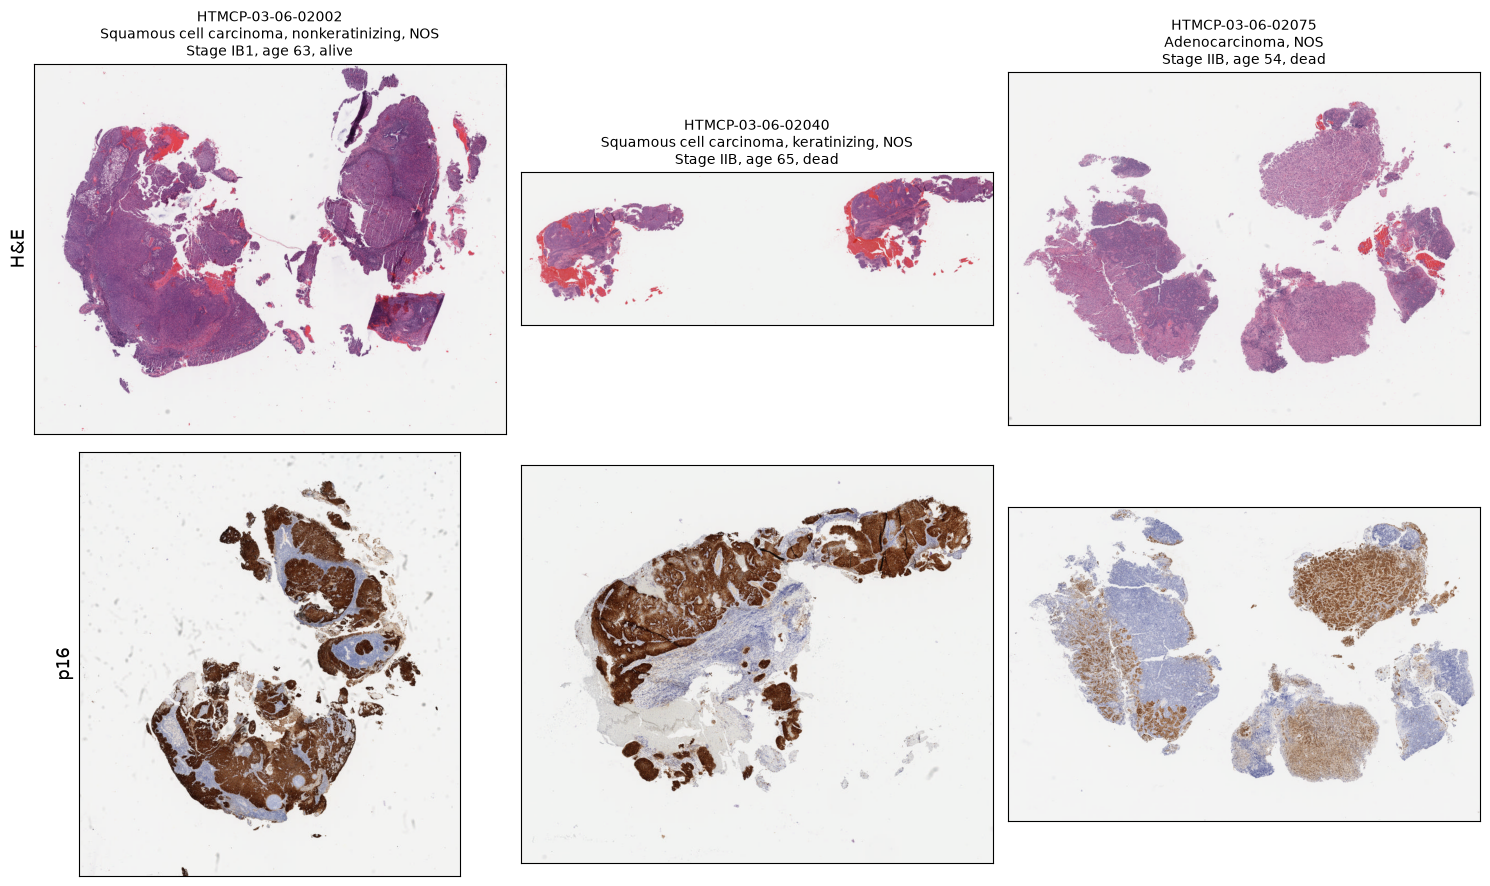

In [9]:
fig, axes = plt.subplots(2, len(examples), figsize=(5 * len(examples), 9))
for col, example in enumerate(examples.itertuples()):
    for row, stain in enumerate(["HE T", "P16 T"]):
        ax = axes[row, col]
        ax.imshow(read_thumbnail(example.PatientID, stain))
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel("H&E" if stain == "HE T" else "p16", fontsize=13)
    axes[0, col].set_title(
        f"{example.PatientID}\n{example.primary_diagnosis}\n{example.figo_stage}, age {example.age_at_diagnosis}, {str(example.vital_status).lower()}",
        fontsize=10,
    )
plt.tight_layout()

To examine any of these slides at full resolution, open it in the IDC slide viewer:

In [10]:
for example in examples.itertuples():
    series_uid = thumbnails.query("PatientID == @example.PatientID and SeriesDescription == 'HE T'")["SeriesInstanceUID"].iloc[0]
    print(example.PatientID, c.get_viewer_URL(seriesInstanceUID=series_uid, viewer_selector="slim"))

HTMCP-03-06-02002 https://viewer.imaging.datacommons.cancer.gov/slim/studies/2.25.259376971094737918552436959895802357539/series/1.3.6.1.4.1.5962.99.1.4103073989.731776438.1773629632709.4.0


HTMCP-03-06-02040 https://viewer.imaging.datacommons.cancer.gov/slim/studies/2.25.26629653880629558559697115123978443849/series/1.3.6.1.4.1.5962.99.1.4100752668.1752454297.1773627311388.4.0


HTMCP-03-06-02075 https://viewer.imaging.datacommons.cancer.gov/slim/studies/2.25.325463198090164036357985097108395815594/series/1.3.6.1.4.1.5962.99.1.4104972708.1685655751.1773631531428.4.0


## Summary

- For collections without a clinical table in `idc-index`, the public GDC API is the source of clinical data, and needs no account.
- GDC project identifiers map to IDC collection identifiers by lowercasing and replacing dashes with underscores; CPTAC is an exception, split into several IDC collections under the single GDC project `CPTAC-3`.
- In `cgci_htmcp_cc` the IDC `PatientID` equals the GDC case `submitter_id`. Before joining another collection, check how many identifiers actually match, since some collections include patients or slides (for example tissue microarrays) that are not GDC cases.
- GDC cases can have several diagnoses; select the primary one with `diagnosis_is_primary_disease`.

To try another collection, change `collection_id` and `gdc_project`, for example to `hcmi_cmdc` and `HCMI-CMDC`. The stain filter and the `figo_stage` column are specific to this collection, so adjust those cells as well. Other GDC clinical fields are documented in the [GDC Data Dictionary](https://docs.gdc.cancer.gov/Data_Dictionary/viewer/).

Please cite the image collection when you use it. Its DOI and license are in the `source_DOI` and `license_short_name` columns of the IDC index:

In [11]:
c.index[c.index["collection_id"] == collection_id][["source_DOI", "license_short_name"]].drop_duplicates()

,source_DOI,license_short_name
91742,10.5281/zenodo.17381404,CC BY 4.0


## Support

If you have any questions about this notebook, please post your question on the [IDC User Forum](https://discourse.canceridc.dev) or [open an issue](https://github.com/ImagingDataCommons/IDC-Tutorials/issues/new) in the [IDC Tutorials repository](https://github.com/ImagingDataCommons/IDC-Tutorials).

## Acknowledgments

Imaging Data Commons has been funded in whole or in part with Federal funds from the National Cancer Institute, National Institutes of Health, under Task Order No. HHSN26110071 under Contract No. HHSN261201500003I.

If you use IDC in your research, please cite the following publication:

> Fedorov, A., Longabaugh, W. J. R., Pot, D., Clunie, D. A., Pieper, S. D., Gibbs, D. L., Bridge, C., Herrmann, M. D., Homeyer, A., Lewis, R., Aerts, H. J. W., Krishnaswamy, D., Thiriveedhi, V. K., Ciausu, C., Schacherer, D. P., Bontempi, D., Pihl, T., Wagner, U., Farahani, K., Kim, E. & Kikinis, R. _National Cancer Institute Imaging Data Commons: Toward Transparency, Reproducibility, and Scalability in Imaging Artificial Intelligence_. RadioGraphics (2023). https://doi.org/10.1148/rg.230180

The clinical data in this notebook come from the NCI Genomic Data Commons:

> Heath, A. P. et al. _The NCI Genomic Data Commons_. Nature Genetics 53, 257-262 (2021). https://doi.org/10.1038/s41588-021-00791-5